# Public health analysis — Global trends

The long view. Two questions in this notebook:

1. **How has global life expectancy evolved since 1950?** — the world series first, then population-weighted regional trajectories.
2. **Are countries converging?** — the distribution of life expectancy across countries, decade by decade, and cross-country dispersion measured the honest way (a balanced panel).

Everything reads `../data/processed/panel.csv`, built by [data_wrangling.ipynb](data_wrangling.ipynb). Figures are saved to `../figures/`.

In [1]:
# Setup block -- same as the other notebooks so each one runs on its own.
from functools import reduce
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#D8DEE4", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.major.size": 0, "ytick.major.size": 0,
    "xtick.labelsize": 10, "ytick.labelsize": 10,
    "axes.labelsize": 10.5, "axes.labelcolor": "#4A5560",
    "axes.titlesize": 15, "axes.titleweight": "bold",
    "axes.titlepad": 14, "axes.titlecolor": "#1A2530",
    "legend.frameon": False, "legend.fontsize": 9.5,
    "figure.dpi": 110, "savefig.dpi": 200,
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

# Paul Tol's colourblind-safe set. Regions keep the same colour in every
# figure of this project, so a reader never has to re-decode a legend.
REGION_COLORS = {
    "Africa": "#EE7733",
    "Asia": "#0077BB",
    "Europe": "#009988",
    "North America": "#33BBEE",
    "South America": "#CC3311",
    "Oceania": "#EE3377",
}
ACCENT, ACCENT_2 = "#0077BB", "#EE7733"
NEUTRAL, NEUTRAL_LIGHT, GRID = "#4A5560", "#9AA7B2", "#E8EDF1"
SOURCE_NOTE = ("Source: Our World in Data (UN WPP 2024, UN IGME 2024, World Bank, "
               "WHO GHO, IHME GBD, Maddison Project). CC BY 4.0.")

def headline(ax, title, subtitle=None):
    """Finding-first title (left, bold), muted subtitle underneath."""
    ax.set_title(title, loc="left", pad=34 if subtitle else 14)
    if subtitle:
        ax.text(0, 1.045, subtitle, transform=ax.transAxes,
                fontsize=10, color=NEUTRAL, va="bottom")

def clean_axis(ax, grid=True, axis="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if grid:
        ax.grid(axis=axis, color=GRID, linewidth=0.7)
        ax.set_axisbelow(True)

def save(fig, name, note=SOURCE_NOTE):
    """Save into ../figures with the source attribution in the bottom corner."""
    if note:
        fig.text(0.006, 0.008, note, fontsize=7.5, color=NEUTRAL_LIGHT, va="bottom")
        try:
            # reserve the bottom strip so the layout engine keeps the x-label
            # clear of the source note
            fig.get_layout_engine().set(rect=(0, 0.042, 1, 0.958))
        except Exception:
            pass  # cosmetic only
    path = f"../figures/{name}.png"
    fig.savefig(path, dpi=200, facecolor="white")
    plt.show()
    print("saved", path)

def line_end_labels(ax, entries, dx_px=9, min_gap_px=15):
    """Direct labels at the right edge of each line. Line-end labels beat a
    legend box, but adjacent end values collide (Europe vs Oceania here), so
    everything is measured in display pixels and overlapping labels get pushed
    apart by a minimum gap."""
    fig = ax.figure
    fig.canvas.draw()   # finalise transforms before measuring
    pts = [ax.transData.transform((e["x"], e["y"])) for e in entries]
    to_frac = ax.transAxes.inverted()
    order = sorted(range(len(entries)), key=lambda i: pts[i][1])
    ys = [pts[i][1] for i in order]
    for k in range(1, len(ys)):
        if ys[k] - ys[k - 1] < min_gap_px:
            ys[k] = ys[k - 1] + min_gap_px
    for k, idx in enumerate(order):
        e = entries[idx]
        fx, fy = to_frac.transform((pts[idx][0] + dx_px, ys[k]))
        ax.annotate(e["text"], xy=(e["x"], e["y"]), xycoords="data",
                    xytext=(fx, fy), textcoords="axes fraction",
                    fontsize=e.get("fontsize", 9.3),
                    fontweight=e.get("weight", "normal"),
                    color=e["color"], va="center")

def weighted_mean(df, value, weight="population"):
    """Population-weighted mean -- otherwise Tuvalu counts as much as China,
    which is not what 'the average person experiences' means."""
    d = df[[value, weight]].dropna()
    return float(np.average(d[value], weights=d[weight])) if len(d) else np.nan

def regional_series(df, value):
    """Population-weighted `value` per region per year."""
    rows = []
    for (year, region), chunk in df.groupby(["year", "region"]):
        rows.append({"year": year, "region": region,
                     "value": weighted_mean(chunk, value)})
    return pd.DataFrame(rows)

panel = pd.read_csv("../data/processed/panel.csv")
world = pd.read_csv("../data/processed/world.csv")
print(f"{panel.country.nunique()} countries · {len(panel):,} rows · "
      f"{panel.year.min()}-{panel.year.max()}")

248 countries · 18,273 rows · 1950-2024


## 1. The world series

One important choice up front: this is **OWID's own "World" aggregate**, not an average I computed. The UN constructs its world life expectancy from the underlying age-specific rates; averaging country values (even population-weighted ones) would not give the same object. I kept those `World` rows aside in data_wrangling.ipynb for exactly this use.

1950: 46.4 · 2019: 72.6 · trough 2021: 70.9 · 2023: 73.2


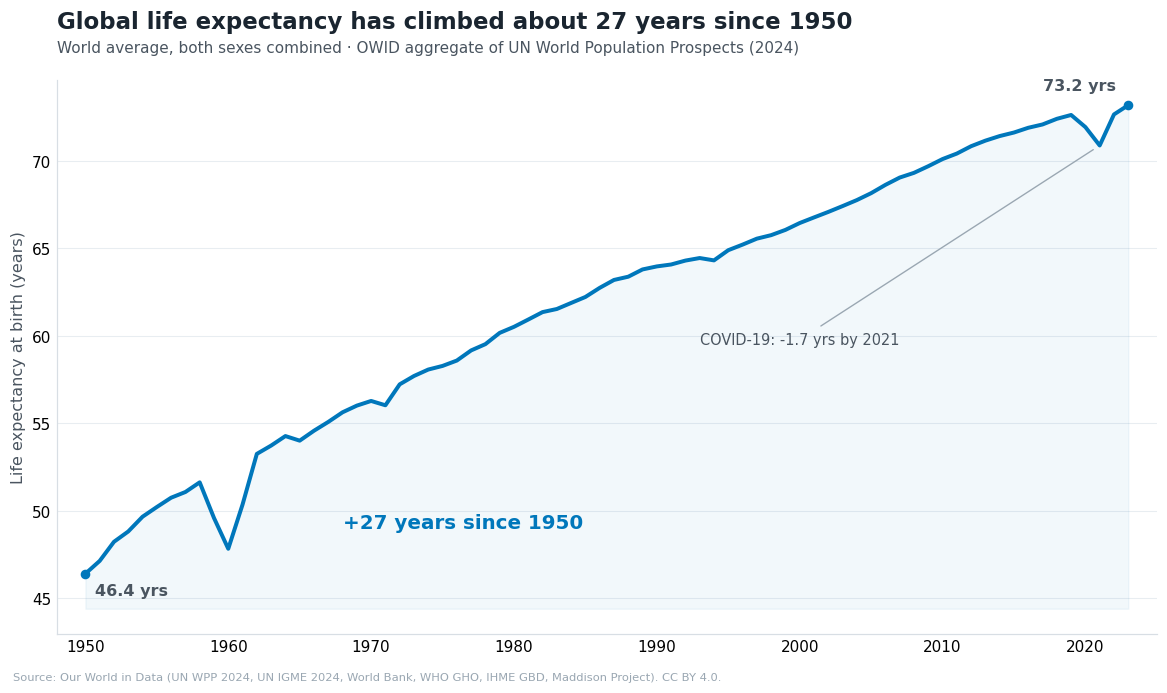

saved ../figures/world_life_expectancy.png


In [2]:
w = world.dropna(subset=["life_expectancy"])
w = w[w["year"].between(1950, 2023)]

first, last = w.iloc[0], w.iloc[-1]
gain = last.life_expectancy - first.life_expectancy

# the COVID interruption, read straight off the series rather than asserted
pre_covid = w[w["year"] <= 2019].iloc[-1]
trough = w[w["year"].between(2020, 2022)]
covid_drop = pre_covid.life_expectancy - trough.life_expectancy.min()
trough_year = int(trough.loc[trough.life_expectancy.idxmin(), "year"])
print(f"1950: {first.life_expectancy:.1f} · 2019: {pre_covid.life_expectancy:.1f} · "
      f"trough {trough_year}: {trough.life_expectancy.min():.1f} · 2023: {last.life_expectancy:.1f}")

fig, ax = plt.subplots(figsize=(10.5, 6.2), constrained_layout=True)
ax.plot(w["year"], w["life_expectancy"], color=ACCENT, linewidth=2.6, zorder=3)
ax.fill_between(w["year"], w["life_expectancy"], w["life_expectancy"].min() - 2,
                color=ACCENT, alpha=0.05, zorder=1)

ax.scatter([first.year, last.year], [first.life_expectancy, last.life_expectancy],
           s=28, color=ACCENT, zorder=4)
ax.annotate(f"{first.life_expectancy:.1f} yrs", (first.year, first.life_expectancy),
            xytext=(6, -14), textcoords="offset points", fontsize=10.5,
            color=NEUTRAL, fontweight="bold")
ax.annotate(f"{last.life_expectancy:.1f} yrs", (last.year, last.life_expectancy),
            xytext=(-8, 10), textcoords="offset points", fontsize=10.5,
            color=NEUTRAL, fontweight="bold", ha="right")
ax.annotate(f"+{gain:.0f} years since {int(first.year)}", xy=(1968, 49),
            fontsize=13, fontweight="bold", color=ACCENT)
ax.annotate(f"COVID-19: -{covid_drop:.1f} yrs by {trough_year}",
            xy=(trough_year, trough.life_expectancy.min()), xytext=(1993, 59.5),
            fontsize=9.5, color=NEUTRAL,
            arrowprops=dict(arrowstyle="-", color=NEUTRAL_LIGHT, lw=0.9,
                            shrinkA=4, shrinkB=5))

ax.set_xlim(1948, 2025)
ax.set_ylabel("Life expectancy at birth (years)")
clean_axis(ax)
headline(ax, f"Global life expectancy has climbed about {gain:.0f} years since {int(first.year)}",
         "World average, both sexes combined · OWID aggregate of UN World Population Prospects (2024)")
save(fig, "world_life_expectancy")

What the chart says — and one thing it doesn't:

- The gain is enormous by any historical standard: **46.4 → 73.2 years between 1950 and 2023**. Most of humanity now lives longer than the longest-lived countries did in 1950.
- Progress was never automatic. The slope flattens in the 1990s, when the HIV/AIDS era in Africa weighed on the world average, and **COVID-19 erased about 1.8 years** between 2019 (72.6) and the 2021 trough (70.9) — a decade of progress gone in two years, largely recovered by 2023.
- The caveat the line can't show: this is *period* life expectancy — a synthetic measure that asks "how long would a newborn live if today's age-specific mortality rates stayed with them for life?" It moves with current conditions, which is exactly why a pandemic dents it.

## 2. Regional trajectories

From here on, "regional average" means **population-weighted** — India dominates Asia's line the way Tuvalu never dominates Oceania's. The lines are computed from the country panel, not taken from OWID.

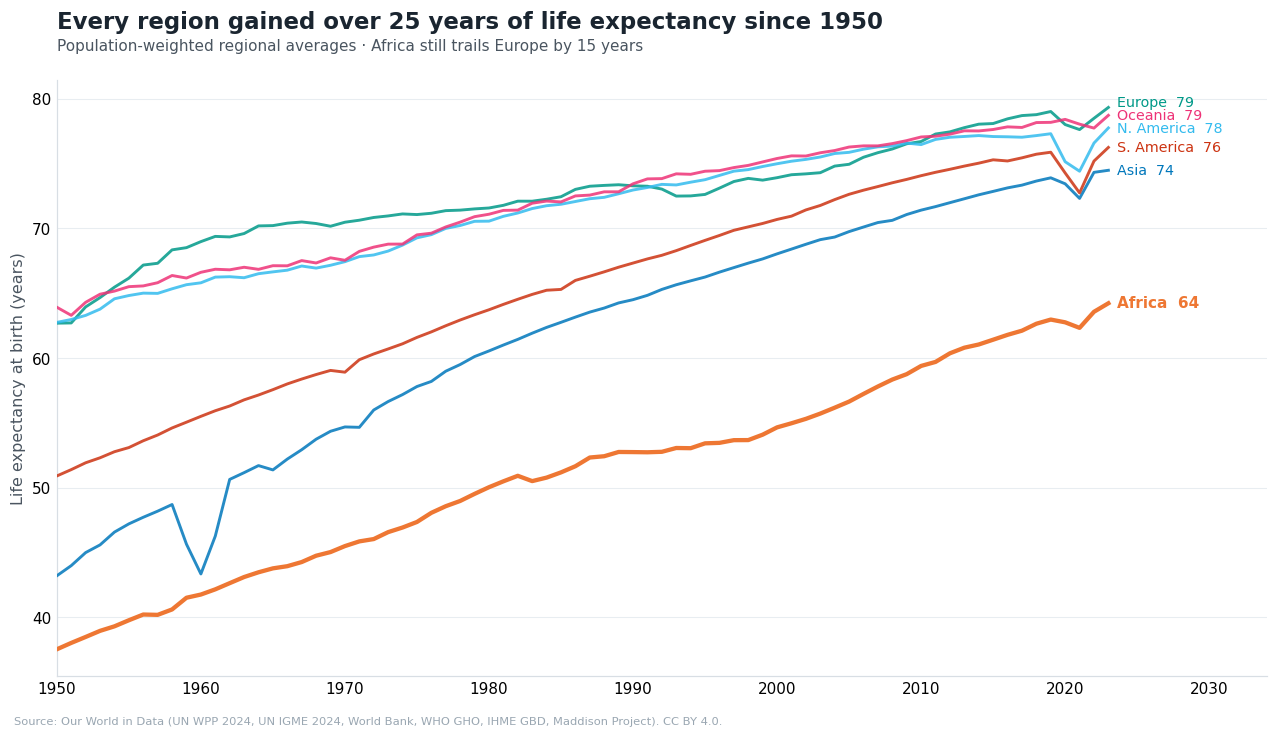

saved ../figures/regional_life_expectancy.png


In [3]:
series = regional_series(panel, "life_expectancy")
series = series[series["year"].between(1950, 2023)]
piv = series.pivot(index="year", columns="region", values="value")

fig, ax = plt.subplots(figsize=(11.5, 6.6), constrained_layout=True)
entries = []
for region in REGION_COLORS:
    if region not in piv.columns:
        continue
    s = piv[region].dropna()
    emph = region == "Africa"          # the story of this chart
    ax.plot(s.index, s.values, color=REGION_COLORS[region],
            linewidth=2.8 if emph else 1.9, alpha=1.0 if emph else 0.85,
            zorder=4 if emph else 3)
    short = {"North America": "N. America", "South America": "S. America"}.get(region, region)
    entries.append(dict(x=s.index[-1], y=s.iloc[-1], text=f"{short}  {s.iloc[-1]:.0f}",
                        color=REGION_COLORS[region], fontsize=10 if emph else 9.3,
                        weight="bold" if emph else "normal"))

gap = piv["Europe"].iloc[-1] - piv["Africa"].iloc[-1]
ax.set_xlim(1950, 2034)
ax.set_ylabel("Life expectancy at birth (years)")
clean_axis(ax)
line_end_labels(ax, entries)
headline(ax, "Every region gained over 25 years of life expectancy since 1950",
         f"Population-weighted regional averages · Africa still trails Europe by {gap:.0f} years")
save(fig, "regional_life_expectancy")

In [4]:
# the table behind the chart
piv.loc[[1950, 1990, 2023]].round(1)

region,Africa,Asia,Europe,North America,Oceania,South America
year,,,,,,
1950,37.5,43.2,62.7,62.7,63.9,50.9
1990,52.7,64.5,73.3,73.0,73.4,67.3
2023,64.2,74.5,79.3,77.7,78.7,76.2


Three things worth taking from that table:

- Every region gained **14 years or more** — this is not rich countries pulling away; everyone moved.
- Asia's 2023 average (74.5) now sits **above Europe's 1990 level** (73.3). The mental category "developing world" dissolved somewhere in the last three decades.
- Africa gained the most in absolute terms (37.5 → 64.2) yet still trails Europe by 15 years. Progress and disparity coexist — both facts belong in any policy summary.

## 3. The country distribution, decade by decade

Regional averages hide the spread within regions. The violins show every country's life expectancy grouped by decade — the whole distribution, not just its centre.

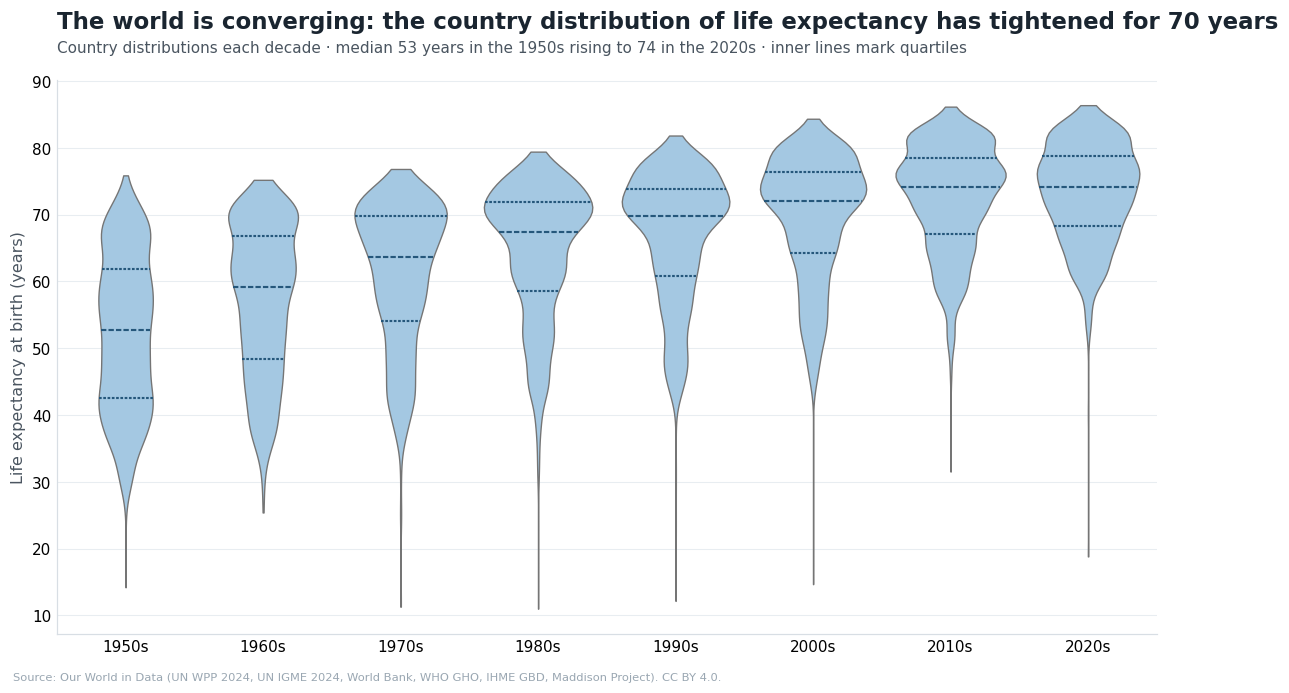

saved ../figures/le_distribution_by_decade.png


In [5]:
import seaborn as sns

d = panel.dropna(subset=["life_expectancy"]).copy()
d = d[d["year"] >= 1950]
d["decade"] = (d["year"] // 10 * 10).astype(int)
decades = sorted(d["decade"].unique())

fig, ax = plt.subplots(figsize=(10.5, 6.2), constrained_layout=True)
sns.violinplot(data=d, x="decade", y="life_expectancy", ax=ax, cut=0,
               inner="quartile", linewidth=0.9, color="#9EC9E8", saturation=0.85)
for line in ax.lines:   # recolour the quartile lines for legibility
    line.set_color("#25577B")
    line.set_linewidth(1.4)

first_med = d[d["decade"] == decades[0]]["life_expectancy"].median()
last_med = d[d["decade"] == decades[-1]]["life_expectancy"].median()

ax.set_xlabel("")
ax.set_ylabel("Life expectancy at birth (years)")
ax.set_xticks(range(len(decades)))
ax.set_xticklabels([f"{dec}s" for dec in decades])
clean_axis(ax)
headline(ax, "The world is converging: the country distribution of life expectancy has tightened for 70 years",
         f"Country distributions each decade · median {first_med:.0f} years in the {decades[0]}s rising to "
         f"{last_med:.0f} in the {decades[-1]}s · inner lines mark quartiles")
save(fig, "le_distribution_by_decade")

The long lower tail of the 1950s — a mass of countries below 40 years — has simply vanished; the median country went from 53 to 74 years. Reading the violins top-down, the distributions also visibly *tighten*: that's σ-convergence, and it deserves its own careful look.

## 4. Convergence, measured properly

The trap with "is the spread falling?" is **composition**. Countries enter the data at different times — mostly poor ones, late. If the sample grows, the standard deviation can fall just because the mix changed. The fix: a **balanced panel** — only countries that report life expectancy in *every* year from 1950 to 2023 — so any fall in dispersion is a real fall in dispersion.

balanced panel: 237 countries · SD 11.7 -> 7.0 years (40% fall)


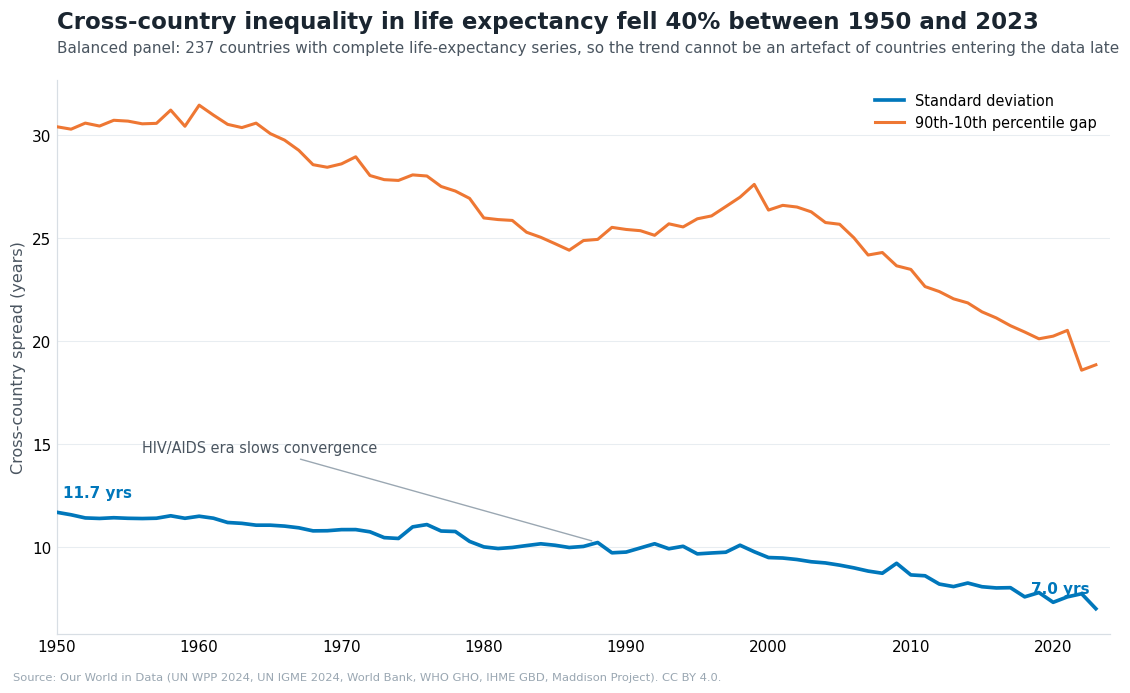

saved ../figures/le_convergence.png


In [6]:
def dispersion_by_year(df, value, start_year, end_year, balanced=True):
    """Cross-country spread of `value` per year. balanced=True keeps only
    countries with data in EVERY year of the window."""
    w = df[df["year"].between(start_year, end_year)]
    if balanced:
        n_years = w["year"].nunique()
        counts = w.dropna(subset=[value]).groupby("country")["year"].nunique()
        w = w[w["country"].isin(counts[counts == n_years].index)]
    stats = (w.groupby("year")[value]
             .agg(sd="std", p10=lambda s: s.quantile(0.10),
                  p90=lambda s: s.quantile(0.90), n="size")
             .reset_index())
    stats["interdecile_range"] = stats["p90"] - stats["p10"]
    return stats

stats = dispersion_by_year(panel, "life_expectancy", 1950, 2023, balanced=True)
start_sd, end_sd = stats["sd"].iloc[0], stats["sd"].iloc[-1]
drop_pct = 100 * (start_sd - end_sd) / start_sd
print(f"balanced panel: {int(stats['n'].iloc[0])} countries · "
      f"SD {start_sd:.1f} -> {end_sd:.1f} years ({drop_pct:.0f}% fall)")

fig, ax = plt.subplots(figsize=(10.5, 6.2), constrained_layout=True)
ax.plot(stats["year"], stats["sd"], color=ACCENT, linewidth=2.4, zorder=3,
        label="Standard deviation")
ax.plot(stats["year"], stats["interdecile_range"], color=ACCENT_2, linewidth=2.0,
        zorder=3, label="90th-10th percentile gap")

ax.annotate(f"{start_sd:.1f} yrs", (stats["year"].iloc[0], start_sd),
            xytext=(4, 10), textcoords="offset points", fontsize=10,
            color=ACCENT, fontweight="bold")
ax.annotate(f"{end_sd:.1f} yrs", (stats["year"].iloc[-1], end_sd),
            xytext=(-4, 10), textcoords="offset points", fontsize=10,
            color=ACCENT, fontweight="bold", ha="right")

# anchor the note to the data: locate the local SD maximum in the AIDS window
window = stats[stats["year"].between(1985, 2005)]
peak = window.loc[window["sd"].idxmax()]
ax.annotate("HIV/AIDS era slows convergence",
            xy=(int(peak["year"]), float(peak["sd"])), xytext=(1956, 14.6),
            fontsize=9.5, color=NEUTRAL,
            arrowprops=dict(arrowstyle="-", color=NEUTRAL_LIGHT, lw=0.9,
                            shrinkA=2, shrinkB=4))

ax.set_ylabel("Cross-country spread (years)")
ax.set_xlim(1950, 2024)
ax.legend(loc="upper right")
clean_axis(ax)
headline(ax, f"Cross-country inequality in life expectancy fell {drop_pct:.0f}% between 1950 and 2023",
         f"Balanced panel: {int(stats['n'].iloc[0])} countries with complete life-expectancy series, "
         "so the trend cannot be an artefact of countries entering the data late")
save(fig, "le_convergence")

Reading it:

- The standard deviation fell from **11.7 to 7.0 years** (about −40%); the 90th–10th percentile gap fell from 30.4 to 18.8 years. Convergence is real, not a composition artefact.
- It was **not monotonic**: dispersion stops falling — even rises slightly — through the AIDS era (the plateau flagged on the chart). When one region takes a shock the others don't, convergence stops. Worth remembering whenever anyone extrapolates a health trend line through a pandemic.
- Convergence in *levels* has a structural ceiling: the leading countries sit in the low-to-mid 80s (Hong Kong 85.5, Japan 84.7, South Korea 84.3 in 2023). Unless the frontier keeps moving, catch-up countries compress against it — cross-country gaps can fall while gaps in *healthy* life expectancy do not.

## Recap

The world got much healthier, everywhere, and country inequality fell by roughly 40%. But averages hide the movers. **[country_comparison.ipynb](country_comparison.ipynb)** takes the country view: who's on top, who gained most since 1990, and the short list that went backwards.